# Online Retail: Customer Segmentation & Recommendation

**Author:** Charlotte Zhu

A UK-based online retailer sells giftware for all occasions, mostly to **wholesale customers**. This notebook asks two
business questions:

1. **Who are our customers?** Segment customers with an **RFM** (Recency, Frequency, Monetary) model and compare
   K-means, K-medoids and hierarchical clustering.
2. **What should we recommend to them?** Build a **user-based collaborative-filtering recommender** that combines
   purchase behaviour and geography, tune it on a validation window, and compare it with simple baselines on a
   held-out test window.

**Data:** [Online Retail II](https://archive.ics.uci.edu/dataset/502/online+retail+ii), UCI Machine Learning
Repository. This notebook uses the 2009-12-01 to 2010-12-09 sheet (525,461 transaction lines).

| Variable | Type | Description |
|---|---|---|
| `Invoice` | Nominal | 6-digit invoice number. Codes starting with **C** are cancellations |
| `StockCode` | Nominal | 5-digit product code |
| `Description` | Nominal | Product name |
| `Quantity` | Numeric | Units per transaction line |
| `InvoiceDate` | Datetime | Date and time of the transaction |
| `Price` | Numeric | Unit price (GBP) |
| `Customer ID` | Nominal | 5-digit customer number |
| `Country` | Nominal | Customer's country |

In [1]:
import sys
import warnings
from pathlib import Path

import kmedoids
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial import ConvexHull
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

sys.path.append("../src")

warnings.filterwarnings("ignore")
DATA = Path("../data/online_retail_II.xlsx")
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)
SEED = 33

sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Data Preparation

### 1.1 Missing values

Of 525,461 lines, **`Customer ID` is missing for 107,927 (20.5%)** and `Description` for 2,928 (0.6%). Both the
clustering and the recommender work at the customer level, so I drop these rows.

525,461 rows x 8 columns


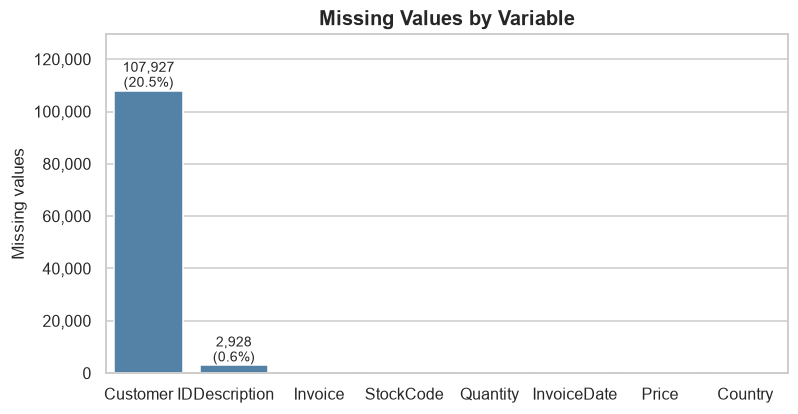

In [2]:
raw = pd.read_excel(DATA, sheet_name=0)
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")

missing = raw.isna().sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=missing.index, y=missing.values, color="steelblue", ax=ax)
for i, v in enumerate(missing.values):
    if v:
        ax.text(i, v, f"{v:,}\n({v / len(raw):.1%})", ha="center", va="bottom", fontsize=9)
ax.set(title="Missing Values by Variable", xlabel=None, ylabel="Missing values")
ax.set_ylim(0, missing.max() * 1.2)
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
save(fig, "01_missing_values")
plt.show()

In [3]:
transactions = raw.dropna().copy()
transactions["Invoice"] = transactions["Invoice"].astype(str)
transactions["StockCode"] = transactions["StockCode"].astype(str)
transactions["Customer ID"] = transactions["Customer ID"].astype(int)
transactions["Amount"] = transactions["Quantity"] * transactions["Price"]
print(f"{len(transactions):,} rows after dropping missing values")

417,534 rows after dropping missing values


### 1.2 Variable overview

In [4]:
numeric_summary = transactions[["Quantity", "Price"]].describe().T[["min", "25%", "50%", "mean", "75%", "max"]]
display(numeric_summary.round(2))
print(f"InvoiceDate: {transactions['InvoiceDate'].min():%Y-%m-%d} to {transactions['InvoiceDate'].max():%Y-%m-%d}")
transactions[["Invoice", "StockCode", "Description", "Customer ID", "Country"]].nunique().to_frame("unique values")

,min,25%,50%,mean,75%,max
Quantity,-9360.0,2.00,4.00,12.76,12.00,19152.00
Price,0.0,1.25,1.95,3.89,3.75,25111.09


InvoiceDate: 2009-12-01 to 2010-12-09


,unique values
Invoice,23587
StockCode,4031
Description,4459
Customer ID,4383
Country,37


`Quantity` and `Price` are both **heavily skewed with extreme outliers**. Quantity ranges from −9,360 (returns) to
19,152, and price reaches £25,111 (manual adjustments). The left panels show the central 98% of the data and the right
panels show everything on a log scale.

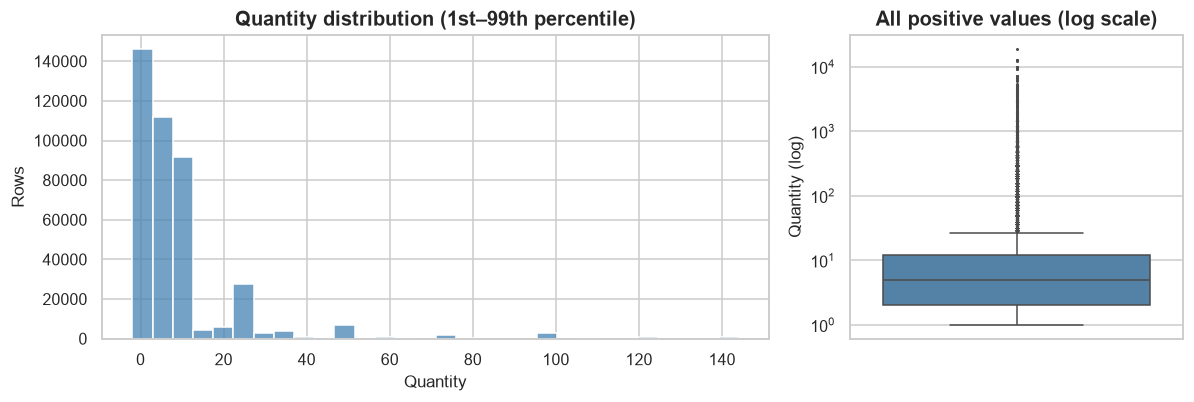

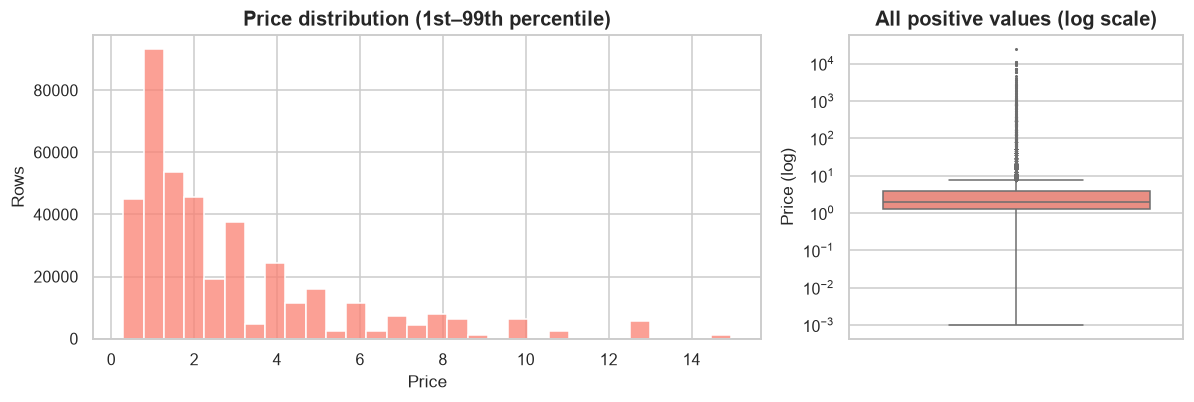

In [5]:
def dist_panel(col, color, title):
    s = transactions[col]
    lo, hi = s.quantile([0.01, 0.99])
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [2, 1]})
    sns.histplot(s[s.between(lo, hi)], bins=30, color=color, ax=axes[0])
    axes[0].set(title=f"{title} distribution (1st–99th percentile)", xlabel=title, ylabel="Rows")
    sns.boxplot(y=s[s > 0], color=color, ax=axes[1], fliersize=1)
    axes[1].set_yscale("log")
    axes[1].set(title="All positive values (log scale)", ylabel=f"{title} (log)")
    fig.tight_layout()
    return fig

save(dist_panel("Quantity", "steelblue", "Quantity"), "02_quantity_distribution"); plt.show()
save(dist_panel("Price", "salmon", "Price"), "03_price_distribution"); plt.show()

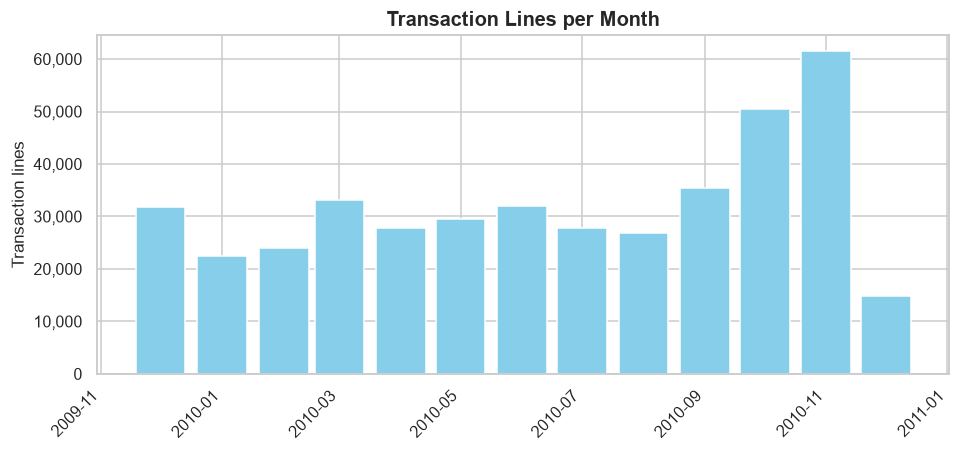

In [6]:
monthly = transactions.set_index("InvoiceDate").resample("MS")["Invoice"].size()
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(monthly.index, monthly.values, width=25, color="skyblue")
ax.set(title="Transaction Lines per Month", xlabel=None, ylabel="Transaction lines")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%Y-%m"))
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
save(fig, "04_monthly_transactions")
plt.show()

Volume climbs steadily through the autumn and **peaks in Sep–Nov ahead of Christmas**, as expected for a gift wholesaler.

## 2. Descriptive Analysis

Summary statistics alone don't explain the business behind the outliers, so I classify **transactions** by type and
**stock codes** by product type.

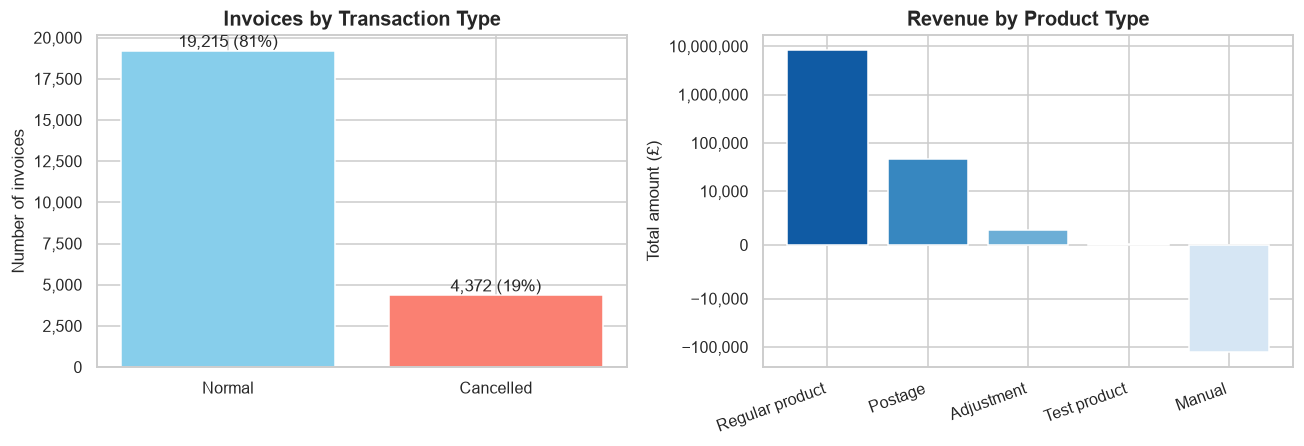

,Total amount
product_type,
Regular product,"£8,426,483"
Postage,"£45,521"
Adjustment,"£2,769"
Test product,£204
Manual,"£-126,768"


In [7]:
transactions["order_type"] = np.where(transactions["Invoice"].str.startswith("C"), "Cancelled", "Normal")
by_type = transactions.groupby("order_type")["Invoice"].nunique().reindex(["Normal", "Cancelled"])

product_type_map = {"M": "Manual", "TEST001": "Test product", "TEST002": "Test product",
                    "ADJUST": "Adjustment", "ADJUST2": "Adjustment", "POST": "Postage"}
transactions["product_type"] = transactions["StockCode"].map(product_type_map).fillna("Regular product")
by_product = transactions.groupby("product_type")["Amount"].sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].bar(by_type.index, by_type.values, color=["skyblue", "salmon"])
axes[0].set(title="Invoices by Transaction Type", ylabel="Number of invoices")
for i, v in enumerate(by_type.values):
    axes[0].text(i, v, f"{v:,} ({v / by_type.sum():.0%})", ha="center", va="bottom")

axes[1].bar(by_product.index, by_product.values, color=sns.color_palette("Blues_r", len(by_product)))
axes[1].set(title="Revenue by Product Type", ylabel="Total amount (£)")
axes[1].set_yscale("symlog", linthresh=1e4)
plt.setp(axes[1].get_xticklabels(), rotation=20, ha="right")
for ax in axes:
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
fig.tight_layout()
save(fig, "05_transaction_and_product_type")
plt.show()
by_product.map("£{:,.0f}".format).to_frame("Total amount")

- **Transaction type:** normal invoices (19,215) outnumber cancellations (4,372) by more than 4 to 1, but a
  **~19% cancellation rate** (by invoice count) is high. It is worth investigating the causes (stock-outs, payment failures, quality).
- **Product type:** regular products make up nearly all revenue (> £8M). The remaining lines are postage, manual
  entries, adjustments, and even **test products in the production system**, which should be separated out. Their
  total value is negligible, so the rest of the analysis treats all stock codes the same.

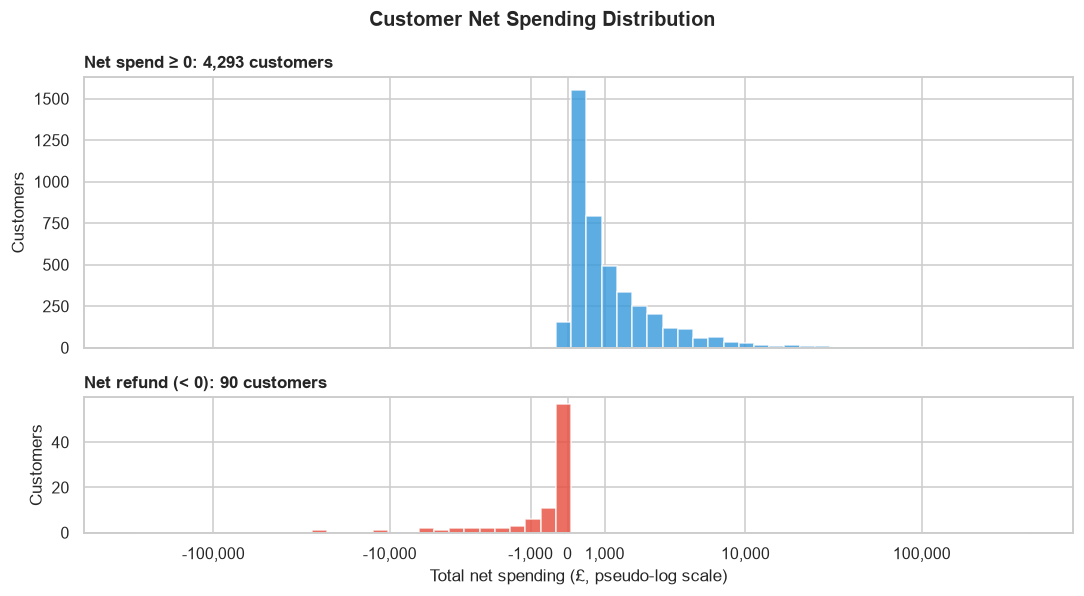

count      4383.0
mean       1905.0
std        8519.0
min      -25111.0
25%         285.0
50%         656.0
70%        1353.0
90%        3532.0
99%       19444.0
max      341777.0
Name: total_spent, dtype: float64

In [8]:
by_customer = transactions.groupby("Customer ID").agg(
    invoices=("Invoice", "nunique"), total_spent=("Amount", "sum"))
by_customer["sign"] = np.where(by_customer["total_spent"] >= 0, "Net spend ≥ 0", "Net refund (< 0)")

# Pseudo-log axis (like scales::pseudo_log_trans): linear near 0, logarithmic in both tails
SIGMA = 1000
fwd = lambda x: np.arcsinh(np.asarray(x) / (2 * SIGMA))
ticks = [-100_000, -10_000, -1_000, 0, 1_000, 10_000, 100_000]

fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
bins = np.linspace(fwd(-3e5), fwd(4e5), 60)
for ax, (label, color) in zip(axes, [("Net spend ≥ 0", "#3498DB"), ("Net refund (< 0)", "#E74C3C")]):
    vals = by_customer.loc[by_customer["sign"] == label, "total_spent"]
    ax.hist(fwd(vals), bins=bins, color=color, alpha=0.8)
    ax.set_ylabel("Customers")
    ax.set_title(f"{label}: {len(vals):,} customers", fontsize=11, loc="left")
axes[1].set_xticks(fwd(ticks), [f"{t:,}" for t in ticks])
axes[1].set_xlabel("Total net spending (£, pseudo-log scale)")
fig.suptitle("Customer Net Spending Distribution", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "06_customer_spending")
plt.show()
by_customer["total_spent"].describe(percentiles=[0.25, 0.5, 0.7, 0.9, 0.99]).round(0)

The median customer spends about **£650**, and 73% spend less than £1,500, but the largest wholesalers spend more
than £100K. A small group of **90 customers (2%) has a net refund** (total < 0), meaning their returns exceed their
purchases in this window. These accounts are worth tracing back to specific orders to check for quality, fulfilment
or seasonal-return problems.

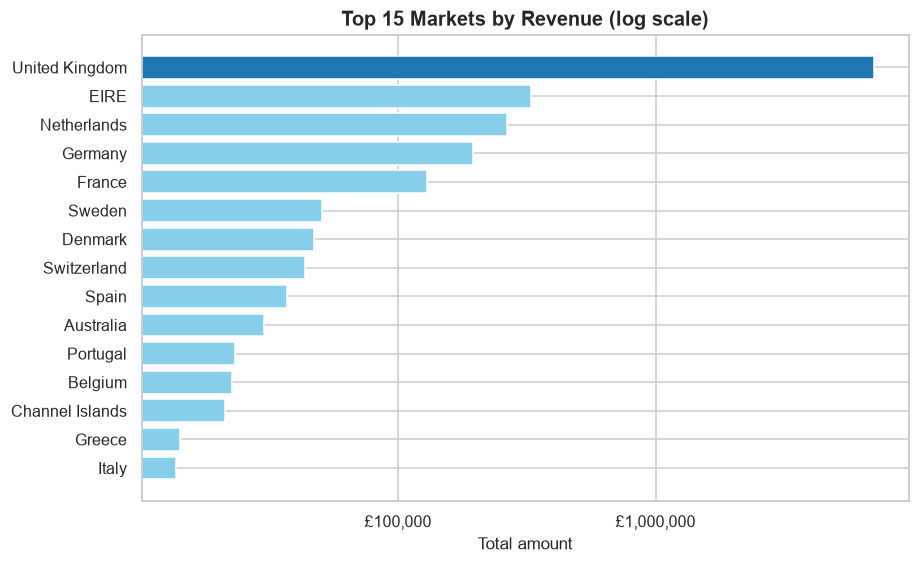

UK share of total revenue: 84.3%


In [9]:
by_country = transactions.groupby("Country")["Amount"].sum().sort_values(ascending=False)
top15 = by_country.head(15)[::-1]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top15.index, top15.values, color=["#1F77B4" if c == "United Kingdom" else "skyblue" for c in top15.index])
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("£{x:,.0f}"))
ax.set(title="Top 15 Markets by Revenue (log scale)", xlabel="Total amount")
save(fig, "07_top_markets")
plt.show()
print(f"UK share of total revenue: {by_country['United Kingdom'] / by_country.sum():.1%}")

Revenue is **heavily concentrated in the UK home market**, which brings in about 84% of the total. The retailer has
barely reached most foreign markets. For core EU markets (Ireland, Netherlands, Germany, France), localization of
payments, logistics and marketing is the obvious growth lever.

## 3. RFM Customer Segmentation

### 3.1 Feature engineering

For each customer, with the reference date 2010-12-10:

- **Recency**: days since the most recent invoice
- **Frequency**: number of distinct invoices
- **Monetary**: total net spend

About 70% of customers spend less than £1,500, while the largest spend more than £100K. To stop a few whales
dominating the clusters, I apply a **pseudo-log transform**, $\text{sign}(x)\cdot\ln(1+|x|)$. It keeps the sign
(net refunders stay negative) and compresses the range. All three features are then z-score standardized.

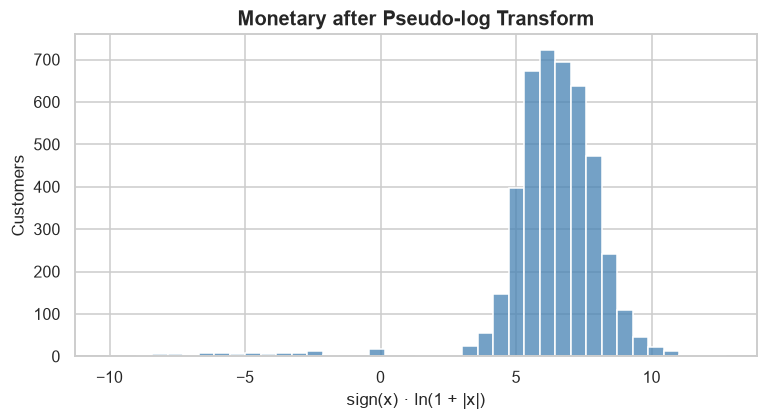

,recency,frequency,monetary
count,4383.00,4383.00,4383.00
mean,-0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-0.92,-0.44,-7.80
25%,-0.76,-0.44,-0.32
50%,-0.40,-0.24,0.07
75%,0.47,0.06,0.51
max,2.88,26.33,3.03


In [10]:
transactions["days_ago"] = (pd.Timestamp("2010-12-10") - transactions["InvoiceDate"].dt.normalize()).dt.days
rfm = transactions.groupby("Customer ID").agg(
    recency=("days_ago", "min"), frequency=("Invoice", "nunique"), monetary=("Amount", "sum"))

pseudo_log = lambda x: np.sign(x) * np.log1p(np.abs(x))
rfm["monetary"] = pseudo_log(rfm["monetary"])

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.histplot(rfm["monetary"], bins=40, color="steelblue", ax=ax)
ax.set(title="Monetary after Pseudo-log Transform", xlabel="sign(x) · ln(1 + |x|)", ylabel="Customers")
save(fig, "08_monetary_pseudolog")
plt.show()

rfm_std = (rfm - rfm.mean()) / rfm.std()          # z-score (same as R's scale())
X = rfm_std.values
rfm_std.describe().round(2)

### 3.2 Choosing *k*: elbow method

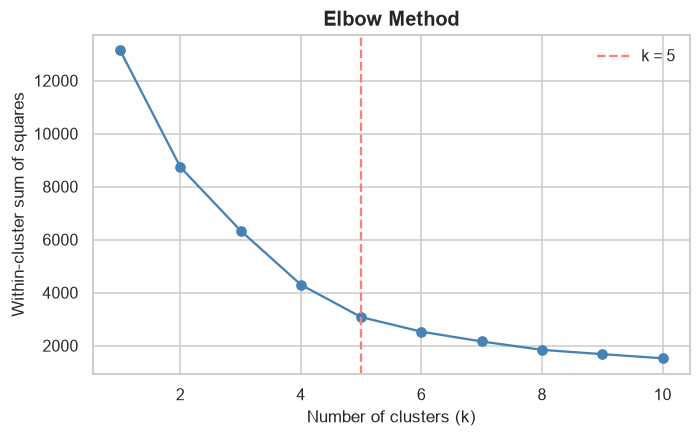

In [11]:
wcss = [KMeans(k, n_init=5, random_state=SEED).fit(X).inertia_ for k in range(1, 11)]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, 11), wcss, "o-", color="steelblue")
ax.axvline(5, color="salmon", ls="--", label="k = 5")
ax.set(title="Elbow Method", xlabel="Number of clusters (k)", ylabel="Within-cluster sum of squares")
ax.legend(frameon=False)
save(fig, "09_elbow")
plt.show()

WCSS drops sharply up to **k = 5** and flattens after that, so adding more clusters doesn't separate the data much
further. I use k = 5.

### 3.3 K-means segments

In [12]:
K = 5
km = KMeans(K, n_init=20, random_state=SEED).fit(X)
rfm_std["km_cluster"] = km.labels_

profile = rfm_std.groupby("km_cluster")[["recency", "frequency", "monetary"]].mean()
profile["customers"] = rfm_std["km_cluster"].value_counts()

# Name segments from their centroid profile
def name_segments(p: pd.DataFrame) -> dict:
    names, rest = {}, set(p.index)
    def take(idx, name):
        names[idx] = name; rest.discard(idx)
    take(p.loc[list(rest), "frequency"].idxmax(), "Champions")
    take(p.loc[list(rest), "monetary"].idxmin(), "Dormant / low value")
    take(p.loc[list(rest), "recency"].idxmax(), "At risk")
    take(p.loc[list(rest), "frequency"].idxmax(), "High potential")
    for i in rest:
        names[i] = "Steady core"
    return names

segment_names = name_segments(profile)
rfm_std["segment"] = rfm_std["km_cluster"].map(segment_names)
segment_order = ["Champions", "High potential", "Steady core", "At risk", "Dormant / low value"]
profile = profile.rename(index=segment_names).loc[segment_order]
profile.round(3)

,recency,frequency,monetary,customers
km_cluster,,,,
Champions,-0.886,11.342,2.151,18
High potential,-0.722,1.024,0.966,675
Steady core,-0.443,-0.199,0.062,2595
At risk,1.544,-0.350,-0.330,989
Dormant / low value,1.190,-0.307,-4.951,106


In [13]:
# Raw-unit view of the same segments (easier to read for business stakeholders)
raw_profile = (
    transactions.groupby("Customer ID")
    .agg(recency_days=("days_ago", "min"), invoices=("Invoice", "nunique"), net_spend=("Amount", "sum"))
    .join(rfm_std["segment"])
    .groupby("segment")
    .agg(customers=("invoices", "size"), median_recency_days=("recency_days", "median"),
         median_invoices=("invoices", "median"), median_net_spend=("net_spend", "median"),
         total_net_spend=("net_spend", "sum"))
    .loc[segment_order]
)
raw_profile["revenue_share"] = raw_profile["total_net_spend"] / raw_profile["total_net_spend"].sum()
raw_profile.style.format({"median_net_spend": "£{:,.0f}", "total_net_spend": "£{:,.0f}",
                          "revenue_share": "{:.1%}", "median_recency_days": "{:.0f}", "median_invoices": "{:.0f}"})

,customers,median_recency_days,median_invoices,median_net_spend,total_net_spend,revenue_share
segment,,,,,,
Champions,18,4,106,"£48,373","£1,516,590",18.2%
High potential,675,11,13,"£3,952","£4,020,270",48.2%
Steady core,2595,40,3,£681,"£2,422,337",29.0%
At risk,989,232,1,£282,"£483,665",5.8%
Dormant / low value,106,239,1,£-59,"£-94,653",-1.1%


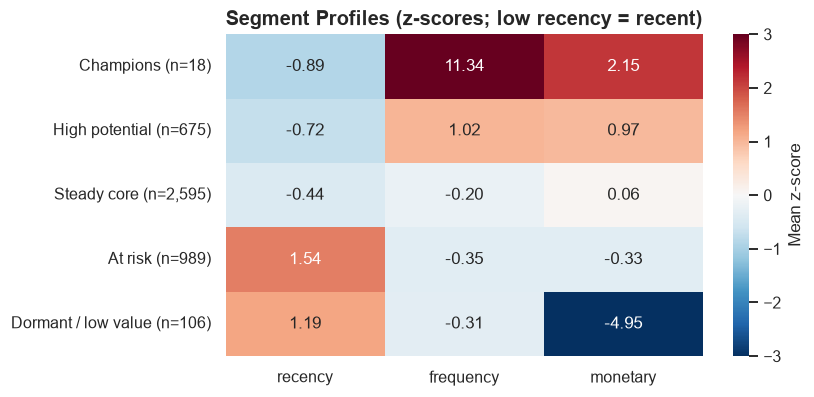

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.8))
sns.heatmap(profile[["recency", "frequency", "monetary"]], annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-3, vmax=3, cbar_kws={"label": "Mean z-score"}, ax=ax)
ax.set_yticklabels([f"{s} (n={n:,})" for s, n in zip(profile.index, profile["customers"])], rotation=0)
ax.set(title="Segment Profiles (z-scores; low recency = recent)", xlabel=None, ylabel=None)
save(fig, "10_segment_profiles")
plt.show()

| Segment | Size | Profile | Suggested action |
|---|---|---|---|
| **Champions** | 18 | Most recent, frequency z ≈ +11, highest spend | Very few customers but a large share of revenue. Give them white-glove treatment: dedicated account managers, custom gift boxes, early access. |
| **High potential** | ~675 | Recent, frequent, above-average spend on all three | The pipeline for future Champions. Use spend-milestone rewards ("spend £X, get Y") to grow them. |
| **Steady core** | ~2,600 | Fairly recent, about average frequency and spend | The largest group, but conservative. Use member days and personalized recommendations to raise frequency and basket size. |
| **At risk** | ~990 | Long time since last purchase, low frequency | Showing signs of churn. Run win-back campaigns before they lapse. |
| **Dormant / low value** | ~106 | Inactive with **net refunds** (monetary z ≈ −5) | Low lifetime value. Keep them on low-cost channels only and spend paid acquisition budget on the other four segments. |

### 3.4 Robustness: K-means vs. K-medoids vs. hierarchical clustering

I compare three algorithms using the **silhouette score**, which measures both cohesion within clusters and
separation between them. That indicates how distinct the segments are and how precisely campaigns could target them.

In [15]:
D = squareform(pdist(X))

pam = kmedoids.pam(D, K, random_state=SEED)                                  # K-medoids (PAM)
hc_labels = AgglomerativeClustering(K, linkage="ward").fit_predict(X)        # Ward hierarchical

results = {
    "K-means": km.labels_,
    "K-medoids (PAM)": pam.labels,
    "Hierarchical (Ward)": hc_labels,
}
silhouettes = {name: silhouette_score(D, labels, metric="precomputed") for name, labels in results.items()}
pd.Series(silhouettes, name="silhouette").round(3).to_frame()

,silhouette
K-means,0.465
K-medoids (PAM),0.326
Hierarchical (Ward),0.438


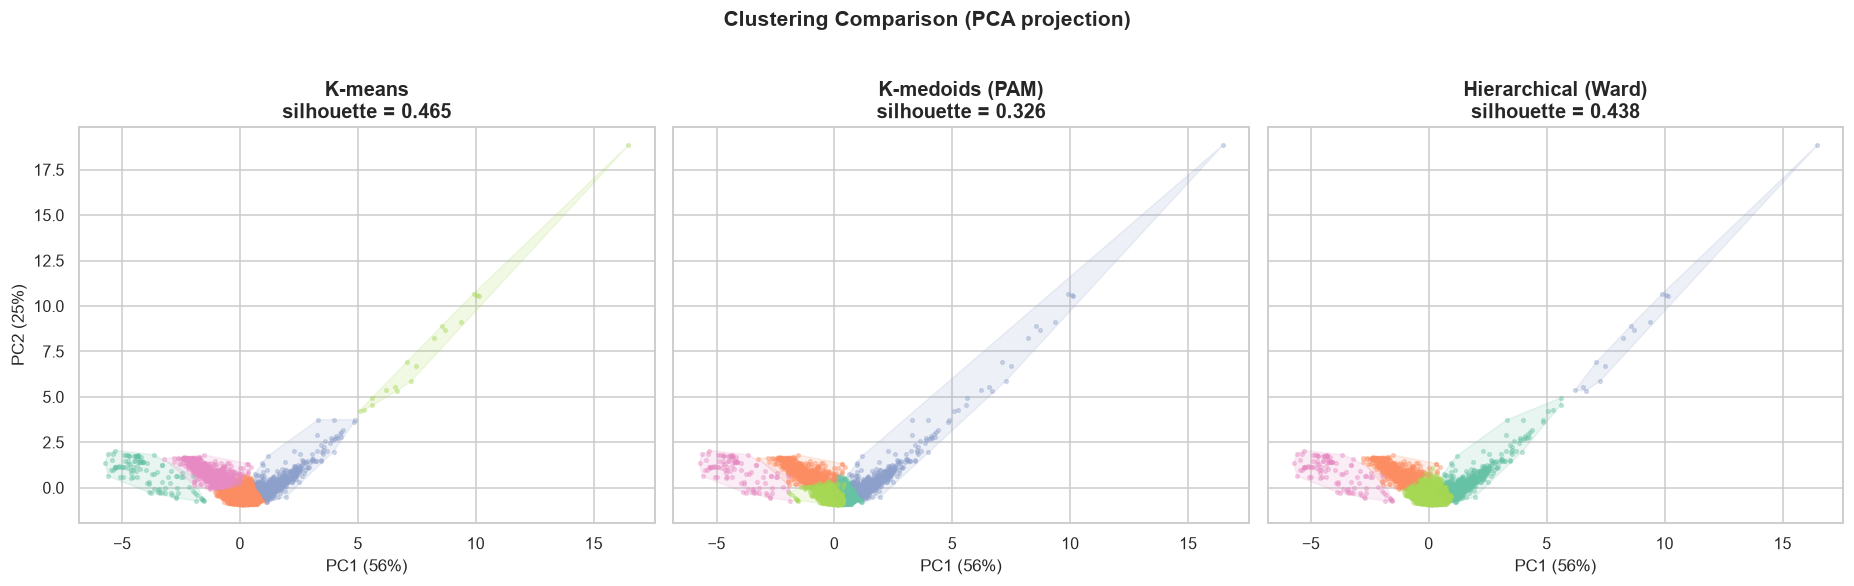

In [16]:
pca = PCA(2, random_state=SEED).fit(X)
Z = pca.transform(X)
palette = sns.color_palette("Set2", K)

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), sharex=True, sharey=True)
for ax, (name, labels) in zip(axes, results.items()):
    for c in range(K):
        pts = Z[labels == c]
        ax.scatter(pts[:, 0], pts[:, 1], s=6, alpha=0.35, color=palette[c])
        if len(pts) >= 3:
            hull = ConvexHull(pts)
            ax.fill(pts[hull.vertices, 0], pts[hull.vertices, 1], color=palette[c], alpha=0.15)
    ax.set_title(f"{name}\nsilhouette = {silhouettes[name]:.3f}")
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
fig.suptitle("Clustering Comparison (PCA projection)", fontweight="bold", fontsize=14, y=1.02)
fig.tight_layout()
save(fig, "11_clustering_comparison")
plt.show()

**K-means scores best (≈ 0.47)**, followed by hierarchical clustering (≈ 0.44), with K-medoids last (≈ 0.33). The
K-medoids projection shows clusters that overlap a lot, which would make targeted campaigns less precise. I keep the
K-means segmentation.

## 4. Recommender System

The goal is to recommend **20 products** to each existing customer for their next purchase window. The
implementation is in [`src/recommender.py`](../src/recommender.py).

### 4.1 Evaluation design

| Choice | Decision | Why |
|---|---|---|
| Split | **Chronological, three-way**, cut by purchase-line volume: train 70%, validation 15%, test 15% | Simulates deployment (predict the future from the past) and keeps the test set untouched until the end |
| Tuning metric | Mean **NDCG@20** on validation | Recommendation is a *ranking* problem. NDCG rewards placing hits near the top, while precision, recall and F1 ignore order |
| Final metrics | **NDCG@20** (primary) and **Recall@20** (secondary) on test | The same metric for tuning and reporting keeps the logic consistent. Recall@20 shows coverage |
| Refit | Similarities for validation come from **train only**. Before testing, the tuned model is refit on train + validation | Uses all information available before the test window without ever looking at test data |
| Users | Customers with at least one purchase in the evaluation window **and** some history before it | Cold start is out of scope |
| Baselines | **Popularity** (top 20 items by distinct buyers) and **personal history** (each user's own most-bought items) | Answers whether the model beats the simplest possible approaches |

In [17]:
from recommender import (TOP_N, PersonalHistoryRecommender, PopularityRecommender, UserCFRecommender,
                         chronological_split, evaluate, ground_truth, load_transactions, per_user_scores, tune)

purchases = load_transactions(raw)
split = chronological_split(purchases, val_size=0.15, test_size=0.15)

def describe(name, part):
    return {"split": name, "from": f"{part['InvoiceDate'].min():%Y-%m-%d}", "to": f"{part['InvoiceDate'].max():%Y-%m-%d}",
            "lines": f"{len(part):,}", "customers": f"{part['Customer ID'].nunique():,}",
            "items": f"{part['StockCode'].nunique():,}"}

pd.DataFrame([describe("train", split.train), describe("validation", split.val),
              describe("test", split.test)]).set_index("split")

,from,to,lines,customers,items
split,,,,,
train,2009-12-01,2010-10-03,"284,463","3,560","3,842"
validation,2010-10-03,2010-11-08,"60,995","1,705","2,734"
test,2010-11-08,2010-12-09,"61,008","1,623","2,782"


### 4.2 Should already-purchased items be recommended?

This has to be decided before modelling, and the same rule must apply to training, tuning and evaluation. The data
shows that **repeat buying is central to this business**:

In [18]:
def repeat_share(history, window):
    truth = ground_truth(history, window)
    past = history.groupby("Customer ID")["StockCode"].agg(set)
    return np.mean([len(items & past[u]) / len(items) for u, items in truth.items()])

print(f"Share of a customer's validation-window items already bought in train: {repeat_share(split.train, split.val):.0%}")
print(f"Share of a customer's test-window items already bought before test:    "
      f"{repeat_share(pd.concat([split.train, split.val]), split.test):.0%}")

Share of a customer's validation-window items already bought in train: 35%
Share of a customer's test-window items already bought before test:    44%


More than a third of what a wholesale customer buys next is **replenishment** of items they already stock. Filtering
out previously purchased items would discard those true positives and make the model look worse on a task that
matters to the business. So **previously purchased items stay eligible for recommendation and count as hits**, for
every model and every split.

This choice also makes "just recommend what they bought before" a strong baseline that the model has to beat. To
compete with it, the CF model gets one extra parameter, **α**, which blends the customer's own purchase history into
the neighbourhood score:

$$\text{score}(i) = (1-\alpha)\,\frac{\text{cf}(i)}{\max \text{cf}} + \alpha\,\frac{\text{spend}(u,i)}{\max \text{spend}(u)}, \qquad
\text{cf}(i) = \sum_{v \in N_K(u)} e^{\,s\cdot\cos(u,v)}\,\frac{\text{spend}(v,i)}{\max \text{spend}(v)}$$

With α = 0 this is pure user-based CF. The user profile used for cosine similarity is 0.8 × TF-IDF(spend) +
0.2 × one-hot(country), each L2-normalized.

### 4.3 Hyperparameter tuning on validation

Grid: K ∈ {10, 20, 50, 100, 150, 200, 300} × sharpness s ∈ {0, 1, 3, 5} × α ∈ {0, 0.25, 0.5, 0.75}. Every model in
the grid is fit on **train only** and scored by NDCG@20 on validation.

In [19]:
val_truth = ground_truth(split.train, split.val)
cf_train = UserCFRecommender().fit(split.train)
grid = tune(cf_train, val_truth,
            k_grid=(10, 20, 50, 100, 150, 200, 300), sharpness_grid=(0, 1, 3, 5), alpha_grid=(0.0, 0.25, 0.5, 0.75))

best_cf = grid[grid["alpha"] == 0].iloc[0]
best_hybrid = grid.iloc[0]
print(f"Validation users: {len(val_truth):,}")
print(f"Best pure CF : K={int(best_cf.K)}, s={best_cf.sharpness:g}            NDCG@20={best_cf['NDCG@20']:.4f}")
print(f"Best hybrid  : K={int(best_hybrid.K)}, s={best_hybrid.sharpness:g}, alpha={best_hybrid.alpha:g}  "
      f"NDCG@20={best_hybrid['NDCG@20']:.4f}")
grid.head(8).round(4)

Validation users: 1,272
Best pure CF : K=150, s=5            NDCG@20=0.2503
Best hybrid  : K=150, s=5, alpha=0.5  NDCG@20=0.2862


,K,sharpness,alpha,NDCG@20,Recall@20,users
0,150,5,0.5,0.2862,0.2064,1272
1,200,5,0.5,0.2859,0.2054,1272
2,150,3,0.5,0.2856,0.2049,1272
3,100,3,0.5,0.2856,0.2058,1272
4,100,5,0.5,0.2854,0.2066,1272
5,200,3,0.5,0.2853,0.2044,1272
6,100,1,0.5,0.2849,0.2045,1272
7,100,0,0.5,0.2848,0.2041,1272


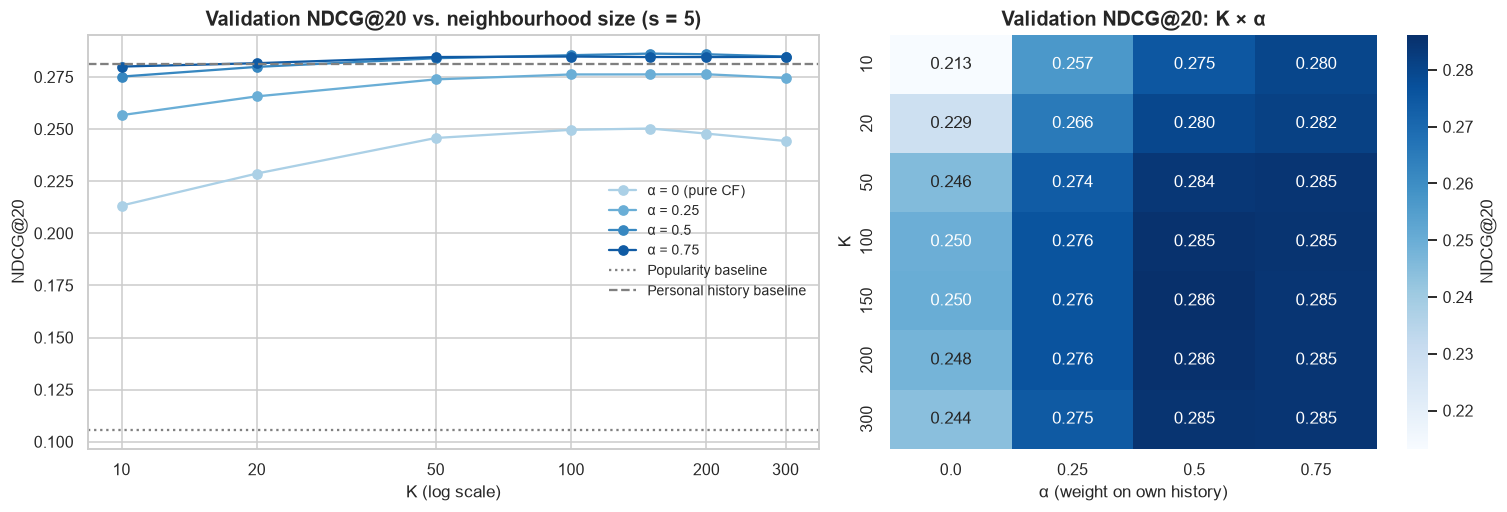

In [20]:
val_baselines = {
    "Popularity": evaluate(PopularityRecommender().fit(split.train).recommend, val_truth),
    "Personal history": evaluate(PersonalHistoryRecommender().fit(split.train).recommend, val_truth),
}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})

# Left: NDCG@20 vs K for each alpha (at the best sharpness)
s_best = best_hybrid.sharpness
for a, color in zip(sorted(grid["alpha"].unique()), sns.color_palette("Blues", 5)[1:]):
    sub = grid[(grid["sharpness"] == s_best) & (grid["alpha"] == a)].sort_values("K")
    axes[0].plot(sub["K"], sub["NDCG@20"], "o-", color=color, label=f"α = {a:g}" + (" (pure CF)" if a == 0 else ""))
for (name, m), ls in zip(val_baselines.items(), [":", "--"]):
    axes[0].axhline(m["NDCG@20"], color="gray", ls=ls, label=f"{name} baseline")
axes[0].set_xscale("log")
axes[0].set_xticks([10, 20, 50, 100, 200, 300], ["10", "20", "50", "100", "200", "300"])
axes[0].set(title=f"Validation NDCG@20 vs. neighbourhood size (s = {s_best:g})", xlabel="K (log scale)",
            ylabel="NDCG@20")
axes[0].legend(frameon=False, fontsize=9, loc="center right")

# Right: heatmap K x alpha at the best sharpness
heat = grid[grid["sharpness"] == s_best].pivot(index="K", columns="alpha", values="NDCG@20")
sns.heatmap(heat, annot=True, fmt=".3f", cmap="Blues", ax=axes[1], cbar_kws={"label": "NDCG@20"})
axes[1].set(title="Validation NDCG@20: K × α", xlabel="α (weight on own history)", ylabel="K")
fig.tight_layout()
save(fig, "12_recommender_tuning")
plt.show()

- **Pure CF improves with a larger neighbourhood** up to about K = 100–150, then declines slowly as more distant
  neighbours add noise. Sharpness matters very little, because exp(s·cos) changes the *weights* but not *which*
  neighbours are chosen.
- **Blending in the customer's own history (α = 0.5) helps a lot** at every K, which fits the replenishment
  pattern above.

### 4.4 Final evaluation on test

All models are refit on **train + validation** with the parameters chosen above, then scored **once** on test.

In [21]:
history = pd.concat([split.train, split.val])
test_truth = ground_truth(history, split.test)

models = {
    "Popularity baseline": PopularityRecommender().fit(history),
    "Personal-history baseline": PersonalHistoryRecommender().fit(history),
    "User-based CF": UserCFRecommender(k=int(best_cf.K), sharpness=best_cf.sharpness).fit(history),
    "CF + own history": UserCFRecommender(k=int(best_hybrid.K), sharpness=best_hybrid.sharpness,
                                          alpha=best_hybrid.alpha).fit(history),
}
scores = {name: per_user_scores(m.recommend, test_truth) for name, m in models.items()}
results = pd.DataFrame({name: s.mean() for name, s in scores.items()}).T
print(f"Test users: {len(test_truth):,}")
results.round(4)

Test users: 1,330


,NDCG@20,Recall@20
Popularity baseline,0.1081,0.0664
Personal-history baseline,0.3141,0.2372
User-based CF,0.2767,0.1951
CF + own history,0.3184,0.2434


In [22]:
# Paired bootstrap (resampling users) for the differences that matter
rng = np.random.default_rng(SEED)

def paired_bootstrap(a, b, metric="NDCG@20", n_boot=2000):
    diff = (scores[a][metric] - scores[b][metric]).to_numpy()
    boots = rng.choice(diff, size=(n_boot, len(diff)), replace=True).mean(axis=1)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return {"comparison": f"{a}  vs  {b}", "Δ NDCG@20": diff.mean(), "95% CI low": lo, "95% CI high": hi}

comparisons = pd.DataFrame([
    paired_bootstrap("User-based CF", "Popularity baseline"),
    paired_bootstrap("CF + own history", "Personal-history baseline"),
    paired_bootstrap("CF + own history", "User-based CF"),
]).set_index("comparison")
comparisons.round(4)

,Δ NDCG@20,95% CI low,95% CI high
comparison,,,
User-based CF vs Popularity baseline,0.1686,0.1580,0.1795
CF + own history vs Personal-history baseline,0.0043,-0.0035,0.0122
CF + own history vs User-based CF,0.0417,0.0365,0.0466


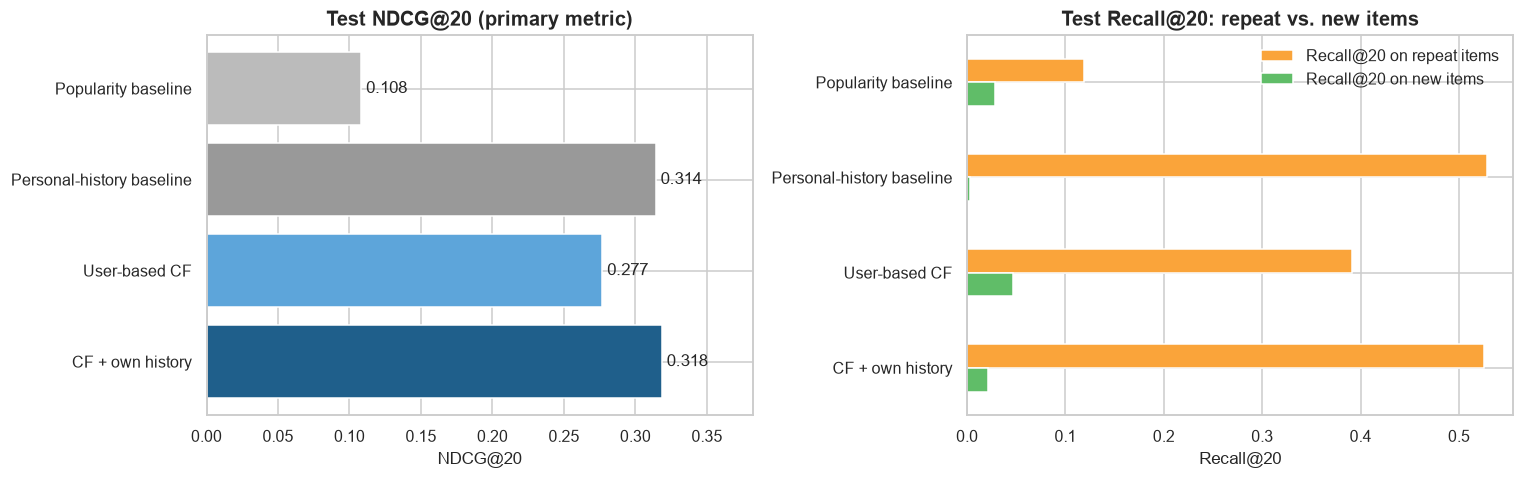

,Recall@20 on repeat items,Recall@20 on new items
Popularity baseline,0.1193,0.0284
Personal-history baseline,0.5288,0.0027
User-based CF,0.3912,0.0464
CF + own history,0.5250,0.0212


In [23]:
# Where do the hits come from? Recall@20 split into repeat items vs items new to the customer
past = history.groupby("Customer ID")["StockCode"].agg(set)

def recall_breakdown(model):
    rep, new = [], []
    for u, actual in test_truth.items():
        recs = set(model.recommend(u)[:TOP_N])
        repeat_items, new_items = actual & past[u], actual - past[u]
        if repeat_items:
            rep.append(len(recs & repeat_items) / len(repeat_items))
        if new_items:
            new.append(len(recs & new_items) / len(new_items))
    return {"Recall@20 on repeat items": np.mean(rep), "Recall@20 on new items": np.mean(new)}

breakdown = pd.DataFrame({name: recall_breakdown(m) for name, m in models.items()}).T

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
colors = ["#BBBBBB", "#999999", "#5DA5DA", "#1F5F8B"]
axes[0].barh(results.index[::-1], results["NDCG@20"][::-1], color=colors[::-1])
for i, v in enumerate(results["NDCG@20"][::-1]):
    axes[0].text(v, i, f" {v:.3f}", va="center")
axes[0].set(title="Test NDCG@20 (primary metric)", xlabel="NDCG@20")
axes[0].set_xlim(0, results["NDCG@20"].max() * 1.2)
breakdown.plot.barh(ax=axes[1], color=["#FAA43A", "#60BD68"])
axes[1].invert_yaxis()
axes[1].set(title="Test Recall@20: repeat vs. new items", xlabel="Recall@20", ylabel=None)
axes[1].legend(frameon=False, loc="upper right")
fig.tight_layout()
save(fig, "13_recommender_test_results")
plt.show()
breakdown.round(4)

In [24]:
# Example: the same customer under the personal-history baseline and the hybrid model
user = max(test_truth, key=lambda u: len(test_truth[u]) if len(past[u]) >= 20 else 0)
desc = purchases.drop_duplicates("StockCode").set_index("StockCode")["Description"]
example = pd.DataFrame({
    "Personal history": models["Personal-history baseline"].recommend(user)[:10],
    "CF + own history": models["CF + own history"].recommend(user)[:10],
}, index=range(1, 11))
for col in example:
    example[col] = [f"{'✔ ' if i in test_truth[user] else ''}{'(new) ' if i not in past[user] else ''}{desc[i]}"
                    for i in example[col]]
print(f"Customer {user}: ✔ = actually bought in the test window, (new) = never bought before")
example

Customer 12748: ✔ = actually bought in the test window, (new) = never bought before


,Personal history,CF + own history
1,✔ REX CASH+CARRY JUMBO SHOPPER,✔ AFGHAN SLIPPER SOCK PAIR
2,✔ 72 SWEETHEART FAIRY CAKE CASES,WHITE CHERRY LIGHTS
3,✔ JUMBO BAG SCANDINAVIAN PAISLEY,PINK CHERRY LIGHTS
4,✔ JUMBO BAG RED WHITE SPOTTY,✔ WHITE HANGING HEART T-LIGHT HOLDER
5,✔ WHITE HANGING HEART T-LIGHT HOLDER,✔ REGENCY CAKESTAND 3 TIER
6,SET/10 PINK SPOTTY PARTY CANDLES,✔ JUMBO BAG RED WHITE SPOTTY
7,PACK OF 72 RETRO SPOT CAKE CASES,DIAMANTE RING ASSORTED IN BOX.
8,✔ ASSTD DESIGN BUBBLE GUM RING,LIGHT PINK CHERRY LIGHTS
9,✔ LUNCH BAG WOODLAND,NATURAL SLATE HEART CHALKBOARD
10,SET/20 RED SPOTTY PAPER NAPKINS,FAIRY CAKE FLANNEL ASSORTED COLOUR


### 4.5 Results

| Model | Test NDCG@20 | Test Recall@20 |
|---|---:|---:|
| Popularity baseline | 0.108 | 0.066 |
| Personal-history baseline | 0.314 | 0.237 |
| User-based CF (K = 150) | 0.277 | 0.195 |
| **CF + own history (K = 150, α = 0.5)** | **0.318** | **0.243** |

- **CF clearly beats popularity.** NDCG@20 is 0.277 vs 0.108, and the paired-bootstrap 95% CI of the gap is
  [0.158, 0.180]. Personalization matters: customers buy very different assortments.
- **Pure CF loses to the personal-history baseline** (0.277 vs 0.314). In wholesale, the best single predictor of next
  month's order is the customer's own past orders, and a model that only looks at neighbours misses that.
- **The hybrid ties the personal-history baseline.** The NDCG gain is +0.004, with a 95% CI of [−0.004, 0.012] that
  includes zero. Most of its hits are repeat items (repeat-item recall 0.525 vs 0.529).
- **Discovery comes from pure CF.** On items new to the customer, pure CF has the highest recall (0.046). That is
  17× the history baseline (0.003), which almost never recommends new items, and above popularity (0.028). The hybrid
  gives up most of that (0.021) in exchange for replenishment accuracy.

**Bottom line:** no single list wins on both jobs. The data supports two different recommendation tasks, replenishment
and discovery, rather than one blended ranking.

### Business implications

- **"Buy again" list:** rank by the customer's own history. It is simple, strong, and statistically as good as the
  tuned hybrid.
- **"You may also like" list:** pure user-based CF, with already-purchased items filtered out *for this slot*. It finds
  new products about 17× more often than history and beats a bestseller list. This is where cross-sell revenue comes
  from.
- **Personalize at all.** Every personalized model is far ahead of a one-size-fits-all bestseller list.

### Next steps

1. **Evaluate the discovery slot on its own terms**: NDCG@20 on new items only, with already-purchased items excluded
   from both recommendations and ground truth, and tune K for that objective.
2. **Time decay and seasonality**: the test window is the pre-Christmas peak, so weight recent and same-season
   purchases more heavily.
3. **Implicit-feedback models** (ALS / BPR) or item-based CF, compared under the same protocol.
4. **Segment-aware tuning**: for example, a different α for *Champions* (mostly replenishment) than for *High
   potential* customers (more discovery).